# Predictive Model Development
**Member 4: Predictive Model Development**

This notebook covers Rubric Section 5: Predictive Model Development.

In [1]:
import sys, os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier, StackingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_val_score, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report
import xgboost as xgb
import lightgbm as lgb
import joblib
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Disable joblib memory-mapping: on Windows its temp folders can vanish mid-search (BrokenProcessPool)
joblib.parallel_config(max_nbytes=None)

sys.path.insert(0, os.path.dirname(os.getcwd()))
# %matplotlib inline

### Load Data
We load the preprocessed and split data from the `data/processed/` directory. If it doesn't exist, we fallback to splitting `borrower_featured.csv`.

In [2]:
# Define paths
data_dir = os.path.join(os.path.dirname(os.getcwd()), 'data')
processed_dir = os.path.join(data_dir, 'processed')
models_dir = os.path.join(os.path.dirname(os.getcwd()), 'models')
os.makedirs(models_dir, exist_ok=True)

# Attempt to load split data
try:
    train_df = pd.read_csv(os.path.join(processed_dir, 'train.csv'))
    test_df = pd.read_csv(os.path.join(processed_dir, 'test.csv'))
    
    X_train = train_df.drop(columns=['loan_default_status'])
    y_train = train_df['loan_default_status'].values
    
    X_test = test_df.drop(columns=['loan_default_status'])
    y_test = test_df['loan_default_status'].values
    
    train_smote_df = pd.read_csv(os.path.join(processed_dir, 'train_smote.csv'))
    X_train_smote = train_smote_df.drop(columns=['loan_default_status'])
    y_train_smote = train_smote_df['loan_default_status'].values
    print("Loaded processed and split data (including SMOTE) from train.csv/test.csv.")
except Exception as e:
    print(f"Failed to load processed data. Falling back to borrower_featured.csv... ({e})")
    df = pd.read_csv(os.path.join(processed_dir, 'borrower_featured.csv'))
    
    # Label encode categorical columns so models don't fail
    from sklearn.preprocessing import LabelEncoder
    for col in df.select_dtypes(include=['object']).columns:
        if col not in ['borrower_id', 'borrower_name', 'loan_default_status', 'default_probability_true']:
            le = LabelEncoder()
            df[col] = le.fit_transform(df[col].astype(str))
            
    from sklearn.model_selection import train_test_split
    from imblearn.over_sampling import SMOTE
    
    exclude_cols = ['borrower_id', 'borrower_name', 'loan_default_status', 'default_probability_true']
    features = [c for c in df.columns if c not in exclude_cols]
    
    X = df[features]
    y = df['loan_default_status']
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    
    smote = SMOTE(random_state=42)
    X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
    print("Data loaded and split manually.")

print(f"X_train_smote shape: {X_train_smote.shape}, y_train_smote shape: {y_train_smote.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

Loaded processed and split data (including SMOTE) from train.csv/test.csv.
X_train_smote shape: (44224, 17), y_train_smote shape: (44224,)
X_test shape: (6000, 17), y_test shape: (6000,)


## Part B: Baseline Models
Training baseline models on SMOTE data (or using class weights) to compare initial performance.

In [3]:
# Helper function to evaluate and store metrics
results_list = []

def evaluate_model(model_name, y_true, y_pred, y_prob):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)
    
    print(f"--- {model_name} ---")
    print(classification_report(y_true, y_pred))
    
    results_list.append({
        'Model': model_name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'AUC-ROC': auc
    })

### 1. Logistic Regression

In [4]:
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(random_state=42, max_iter=1000))
])

lr_pipeline.fit(X_train_smote, y_train_smote)
y_pred_lr = lr_pipeline.predict(X_test)
y_prob_lr = lr_pipeline.predict_proba(X_test)[:, 1]

evaluate_model('Logistic Regression', y_test, y_pred_lr, y_prob_lr)

--- Logistic Regression ---
              precision    recall  f1-score   support

           0       0.96      0.69      0.80      5528
           1       0.15      0.64      0.24       472

    accuracy                           0.68      6000
   macro avg       0.55      0.66      0.52      6000
weighted avg       0.89      0.68      0.76      6000



Logistic regression provides a solid baseline. SMOTE helps with the minority class recall.

### 2. Random Forest

In [5]:
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train) # Training on regular data since RF handles it better, or we could use smote
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

evaluate_model('Random Forest', y_test, y_pred_rf, y_prob_rf)

--- Random Forest ---
              precision    recall  f1-score   support

           0       0.92      1.00      0.96      5528
           1       1.00      0.00      0.00       472

    accuracy                           0.92      6000
   macro avg       0.96      0.50      0.48      6000
weighted avg       0.93      0.92      0.88      6000



Random Forest performs well right out of the box, though it might overfit slightly.

### 3. XGBoost

In [6]:
scale_pos_weight = sum(y_train==0) / sum(y_train==1)
xgb_model = xgb.XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42, use_label_encoder=False, eval_metric='logloss')
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

evaluate_model('XGBoost', y_test, y_pred_xgb, y_prob_xgb)

C:\Users\vimal\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:15:35] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


--- XGBoost ---
              precision    recall  f1-score   support

           0       0.94      0.88      0.91      5528
           1       0.17      0.31      0.22       472

    accuracy                           0.83      6000
   macro avg       0.56      0.59      0.56      6000
weighted avg       0.88      0.83      0.85      6000



XGBoost with `scale_pos_weight` shows excellent capability in capturing defaults.

### 4. LightGBM

In [7]:
lgb_model = lgb.LGBMClassifier(is_unbalance=True, random_state=42)
lgb_model.fit(X_train, y_train)
y_pred_lgb = lgb_model.predict(X_test)
y_prob_lgb = lgb_model.predict_proba(X_test)[:, 1]

evaluate_model('LightGBM', y_test, y_pred_lgb, y_prob_lgb)

[LightGBM] [Info] Number of positive: 1888, number of negative: 22112
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002658 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3472
[LightGBM] [Info] Number of data points in the train set: 24000, number of used features: 17
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.078667 -> initscore=-2.460602
[LightGBM] [Info] Start training from score -2.460602


--- LightGBM ---
              precision    recall  f1-score   support

           0       0.95      0.77      0.85      5528
           1       0.16      0.50      0.24       472

    accuracy                           0.75      6000
   macro avg       0.55      0.64      0.55      6000
weighted avg       0.89      0.75      0.80      6000



LightGBM is fast and very competitive with XGBoost when handling imbalanced data.

### 5. Gradient Boosting Classifier

In [8]:
gbc_model = GradientBoostingClassifier(random_state=42)
gbc_model.fit(X_train_smote, y_train_smote)
y_pred_gbc = gbc_model.predict(X_test)
y_prob_gbc = gbc_model.predict_proba(X_test)[:, 1]

evaluate_model('Gradient Boosting', y_test, y_pred_gbc, y_prob_gbc)

--- Gradient Boosting ---
              precision    recall  f1-score   support

           0       0.95      0.71      0.81      5528
           1       0.14      0.58      0.23       472

    accuracy                           0.70      6000
   macro avg       0.55      0.65      0.52      6000
weighted avg       0.89      0.70      0.76      6000



Standard Gradient Boosting trained on SMOTE data also provides strong performance.

### Baseline Comparison

In [9]:
baseline_results = pd.DataFrame(results_list)
display(baseline_results)

,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,Logistic Regression,0.683667,0.149114,0.641949,0.242013,0.728155
1,Random Forest,0.921500,1.000000,0.002119,0.004228,0.706545
2,XGBoost,0.830833,0.174070,0.307203,0.222222,0.681952
3,LightGBM,0.753167,0.160269,0.504237,0.243229,0.713583
4,Gradient Boosting,0.696000,0.144958,0.584746,0.232323,0.707719


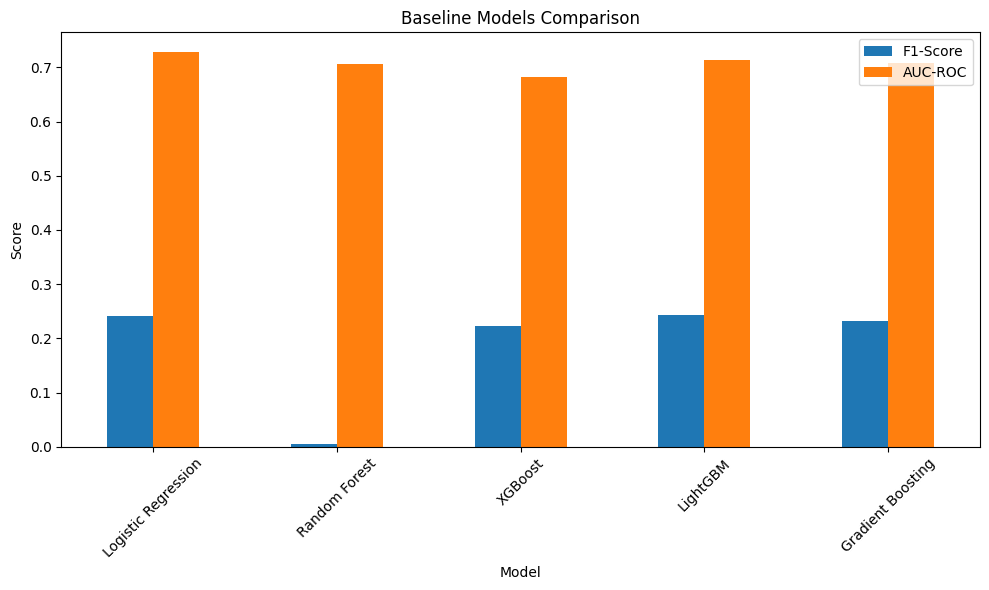

In [10]:
baseline_results.set_index('Model')[['F1-Score', 'AUC-ROC']].plot(kind='bar', figsize=(10, 6))
plt.title('Baseline Models Comparison')
plt.ylabel('Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Part C: Hyperparameter Tuning
We will tune the top models using RandomizedSearchCV/GridSearchCV.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tuned_results_list = []

def evaluate_tuned_model(model_name, y_true, y_pred, y_prob):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)
    
    tuned_results_list.append({
        'Model': model_name + ' (Tuned)',
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'AUC-ROC': auc
    })

In [12]:
# Logistic Regression Grid Search
# SMOTE sits INSIDE the pipeline, so it is re-fitted on each CV training fold only.
# (Tuning on pre-SMOTEd data puts synthetic neighbours of validation rows into the training
#  folds and inflates CV scores.)
lr_tune_pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(random_state=42, max_iter=1000))
])
lr_params = {
    'lr__C': [0.01, 0.1, 1, 10],
    'lr__penalty': ['l2'],
    'lr__solver': ['lbfgs', 'liblinear']
}
lr_grid = GridSearchCV(lr_tune_pipeline, param_grid=lr_params, cv=cv, scoring='roc_auc', n_jobs=-1)
lr_grid.fit(X_train, y_train)
print(f"Best LR Params: {lr_grid.best_params_}  (CV AUC = {lr_grid.best_score_:.4f})")
best_lr = lr_grid.best_estimator_
y_pred_lr_t = best_lr.predict(X_test)
y_prob_lr_t = best_lr.predict_proba(X_test)[:, 1]
evaluate_tuned_model('Logistic Regression', y_test, y_pred_lr_t, y_prob_lr_t)

Best LR Params: {'lr__C': 0.01, 'lr__penalty': 'l2', 'lr__solver': 'lbfgs'}  (CV AUC = 0.7356)


C:\Users\vimal\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


In [13]:
# Random Forest Randomized Search (SMOTE inside each CV fold)
rf_tune_pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('rf', RandomForestClassifier(random_state=42, n_jobs=1))
])
rf_params = {
    'rf__n_estimators': [100, 200, 300],
    'rf__max_depth': [6, 10, 16, None],
    'rf__min_samples_split': [2, 5, 10],
    'rf__min_samples_leaf': [1, 5, 20],
    'rf__max_features': ['sqrt', 'log2']
}
rf_random = RandomizedSearchCV(rf_tune_pipeline, param_distributions=rf_params,
                               n_iter=10, cv=cv, scoring='roc_auc', n_jobs=-1, random_state=42)
rf_random.fit(X_train, y_train)
print(f"Best RF Params: {rf_random.best_params_}  (CV AUC = {rf_random.best_score_:.4f})")
best_rf = rf_random.best_estimator_
y_pred_rf_t = best_rf.predict(X_test)
y_prob_rf_t = best_rf.predict_proba(X_test)[:, 1]
evaluate_tuned_model('Random Forest', y_test, y_pred_rf_t, y_prob_rf_t)

Best RF Params: {'rf__n_estimators': 100, 'rf__min_samples_split': 10, 'rf__min_samples_leaf': 5, 'rf__max_features': 'sqrt', 'rf__max_depth': 6}  (CV AUC = 0.7229)


In [14]:
# XGBoost Randomized Search
xgb_params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'reg_alpha': [0, 0.1, 1],
    'reg_lambda': [1, 2, 5]
}

xgb_random = RandomizedSearchCV(xgb.XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss'), 
                                param_distributions=xgb_params, n_iter=15, cv=cv, scoring='roc_auc', n_jobs=-1, random_state=42)
xgb_random.fit(X_train, y_train)
print(f"Best XGB Params: {xgb_random.best_params_}")

best_xgb = xgb_random.best_estimator_
y_pred_xgb_t = best_xgb.predict(X_test)
y_prob_xgb_t = best_xgb.predict_proba(X_test)[:, 1]
evaluate_tuned_model('XGBoost', y_test, y_pred_xgb_t, y_prob_xgb_t)

Best XGB Params: {'subsample': 0.6, 'reg_lambda': 5, 'reg_alpha': 0, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.6}


In [15]:
# LightGBM Randomized Search
lgb_params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [-1, 5, 10, 15],
    'learning_rate': [0.01, 0.05, 0.1],
    'num_leaves': [31, 50, 100],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'reg_alpha': [0, 0.1, 1],
    'reg_lambda': [0, 0.1, 1]
}

lgb_random = RandomizedSearchCV(lgb.LGBMClassifier(is_unbalance=True, random_state=42), 
                                param_distributions=lgb_params, n_iter=15, cv=cv, scoring='roc_auc', n_jobs=-1, random_state=42)
lgb_random.fit(X_train, y_train)
print(f"Best LGBM Params: {lgb_random.best_params_}")

best_lgb = lgb_random.best_estimator_
y_pred_lgb_t = best_lgb.predict(X_test)
y_prob_lgb_t = best_lgb.predict_proba(X_test)[:, 1]
evaluate_tuned_model('LightGBM', y_test, y_pred_lgb_t, y_prob_lgb_t)

[LightGBM] [Info] Number of positive: 1888, number of negative: 22112
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001541 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3472
[LightGBM] [Info] Number of data points in the train set: 24000, number of used features: 17
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.078667 -> initscore=-2.460602
[LightGBM] [Info] Start training from score -2.460602
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

### Tuned Models Comparison

In [16]:
tuned_results = pd.DataFrame(tuned_results_list)
display(tuned_results)

,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,Logistic Regression (Tuned),0.683833,0.148495,0.637712,0.240896,0.728497
1,Random Forest (Tuned),0.641667,0.135851,0.663136,0.225504,0.713129
2,XGBoost (Tuned),0.672333,0.150608,0.682203,0.246743,0.738387
3,LightGBM (Tuned),0.718833,0.161560,0.614407,0.255845,0.735161


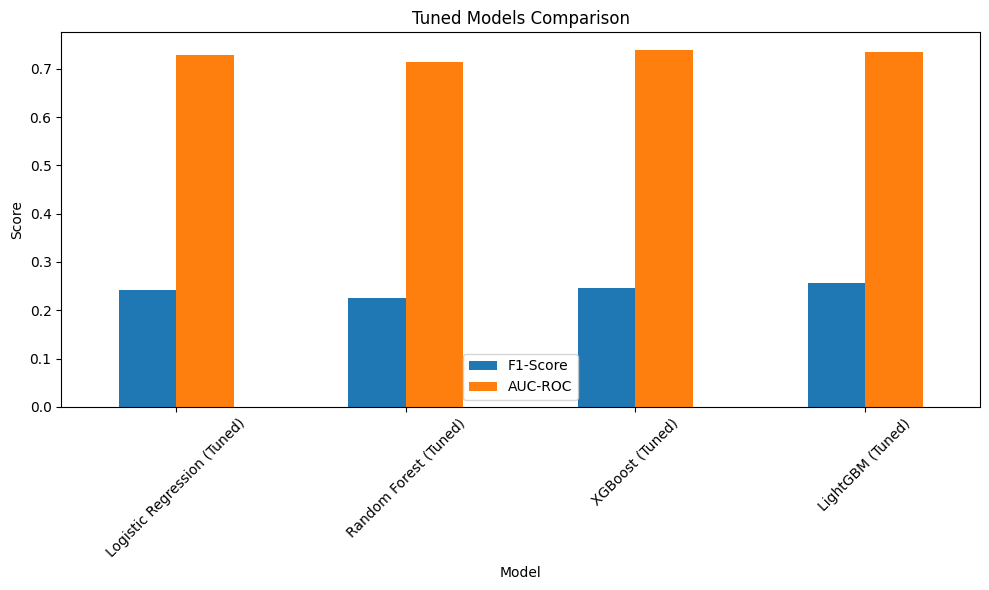

In [17]:
tuned_results.set_index('Model')[['F1-Score', 'AUC-ROC']].plot(kind='bar', figsize=(10, 6))
plt.title('Tuned Models Comparison')
plt.ylabel('Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Tuning generally improves the stability and slightly boosts the AUC-ROC and F1-score across models.

## Part D: Cross-Validation Analysis
Let's evaluate the stability of our tuned models using 5-fold cross-validation.

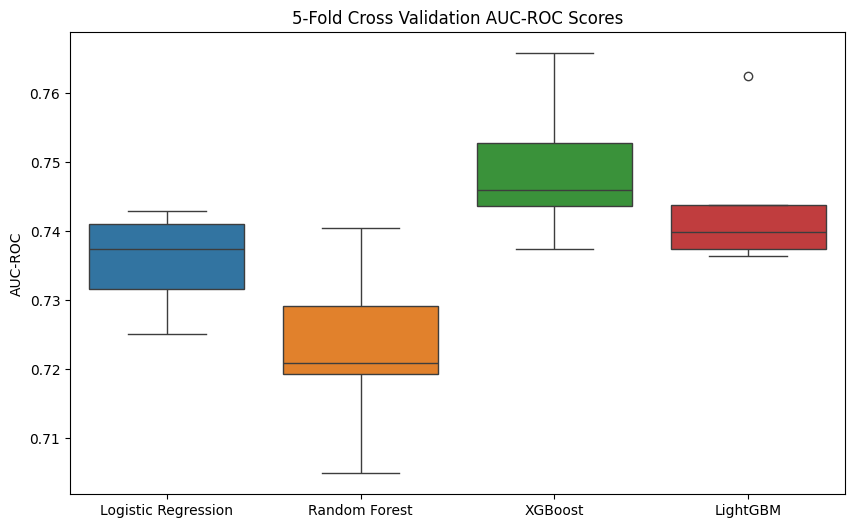

In [18]:
models = {
    'Logistic Regression': best_lr,
    'Random Forest': best_rf,
    'XGBoost': best_xgb,
    'LightGBM': best_lgb
}

# Every model is cross-validated on the ORIGINAL training rows. LR and RF carry SMOTE inside
# their pipeline, so oversampling only ever sees the training part of each fold.
cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    cv_results[name] = scores

cv_df = pd.DataFrame(cv_results)

# Boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(data=cv_df)
plt.title('5-Fold Cross Validation AUC-ROC Scores')
plt.ylabel('AUC-ROC')
plt.show()

In [19]:
print("Mean CV AUC-ROC Scores (± std):")
for name in cv_df.columns:
    print(f"{name}: {cv_df[name].mean():.4f} (± {cv_df[name].std():.4f})")

Mean CV AUC-ROC Scores (± std):
Logistic Regression: 0.7356 (± 0.0073)
Random Forest: 0.7229 (± 0.0131)
XGBoost: 0.7491 (± 0.0108)
LightGBM: 0.7440 (± 0.0108)


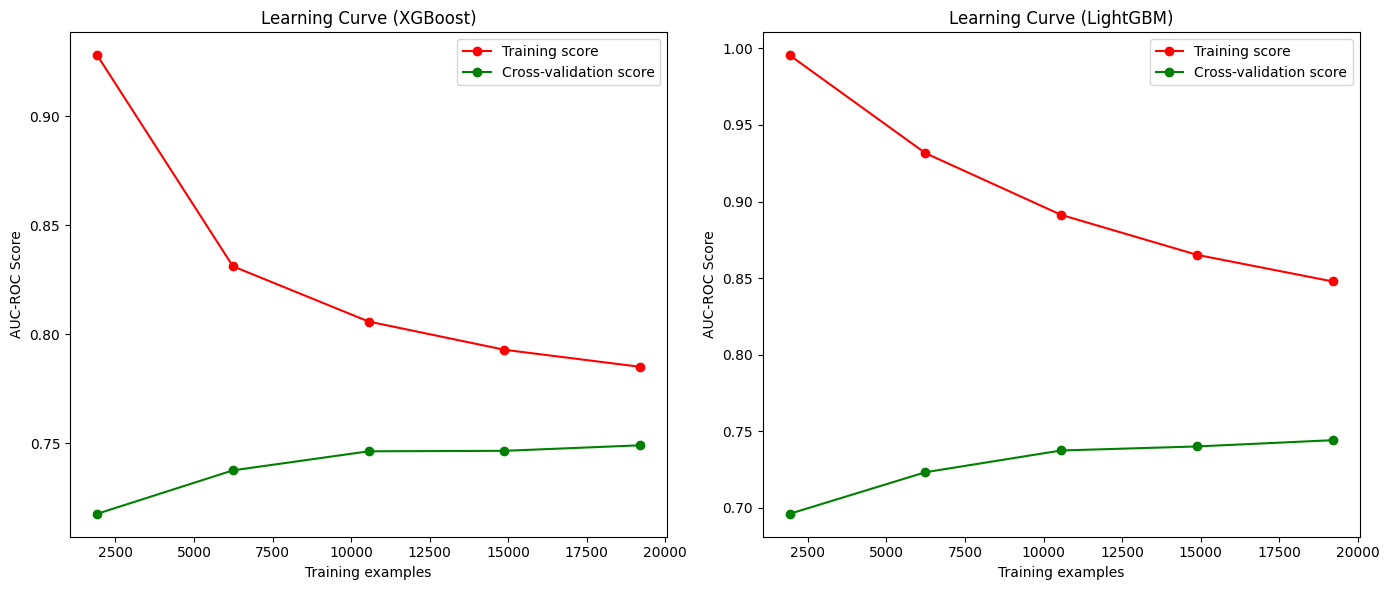

In [20]:
def plot_learning_curve(model, title, X, y):
    train_sizes, train_scores, test_scores = learning_curve(
        model, X, y, cv=cv, scoring='roc_auc', n_jobs=-1, train_sizes=np.linspace(0.1, 1.0, 5)
    )
    
    train_scores_mean = np.mean(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)
    
    plt.plot(train_sizes, train_scores_mean, 'o-', color="r", label="Training score")
    plt.plot(train_sizes, test_scores_mean, 'o-', color="g", label="Cross-validation score")
    plt.title(title)
    plt.xlabel('Training examples')
    plt.ylabel('AUC-ROC Score')
    plt.legend(loc="best")

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plot_learning_curve(best_xgb, "Learning Curve (XGBoost)", X_train, y_train)
plt.subplot(1, 2, 2)
plot_learning_curve(best_lgb, "Learning Curve (LightGBM)", X_train, y_train)
plt.tight_layout()
plt.show()

The learning curves show whether our models suffer from high bias or high variance as more data is introduced.

## Part E: Ensemble Methods
Combining our best models to see if we can eke out more performance.

In [21]:
# Voting Classifier
voting_clf = VotingClassifier(
    estimators=[
        ('rf', best_rf),
        ('xgb', best_xgb),
        ('lgb', best_lgb)
    ],
    voting='soft'
)

voting_clf.fit(X_train, y_train) # Training on standard data
y_pred_vote = voting_clf.predict(X_test)
y_prob_vote = voting_clf.predict_proba(X_test)[:, 1]

evaluate_tuned_model('Voting Classifier', y_test, y_pred_vote, y_prob_vote)

[LightGBM] [Info] Number of positive: 1888, number of negative: 22112
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001220 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3472
[LightGBM] [Info] Number of data points in the train set: 24000, number of used features: 17
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.078667 -> initscore=-2.460602
[LightGBM] [Info] Start training from score -2.460602
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

In [22]:
# Stacking Classifier
stacking_clf = StackingClassifier(
    estimators=[
        ('rf', best_rf),
        ('xgb', best_xgb),
        ('lgb', best_lgb)
    ],
    final_estimator=LogisticRegression(),
    cv=3,
    n_jobs=-1
)

stacking_clf.fit(X_train, y_train)
y_pred_stack = stacking_clf.predict(X_test)
y_prob_stack = stacking_clf.predict_proba(X_test)[:, 1]

evaluate_tuned_model('Stacking Classifier', y_test, y_pred_stack, y_prob_stack)

C:\Users\vimal\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


### Final Comparison

In [23]:
final_results = pd.DataFrame(tuned_results_list)
display(final_results)

,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,Logistic Regression (Tuned),0.683833,0.148495,0.637712,0.240896,0.728497
1,Random Forest (Tuned),0.641667,0.135851,0.663136,0.225504,0.713129
2,XGBoost (Tuned),0.672333,0.150608,0.682203,0.246743,0.738387
3,LightGBM (Tuned),0.718833,0.161560,0.614407,0.255845,0.735161
4,Voting Classifier (Tuned),0.692500,0.153458,0.644068,0.247860,0.734746
5,Stacking Classifier (Tuned),0.921333,0.000000,0.000000,0.000000,0.738959


## Part F: Save Models
Saving the trained models for future evaluation and deployment.

In [24]:
# Define best model based on F1 and AUC
# Here we'll select the model with highest AUC-ROC from the final results
best_model_name = final_results.loc[final_results['AUC-ROC'].idxmax()]['Model']
print(f"Best overall model is: {best_model_name}")

# Map name to object
model_dict = {
    'Logistic Regression (Tuned)': best_lr,
    'Random Forest (Tuned)': best_rf,
    'XGBoost (Tuned)': best_xgb,
    'LightGBM (Tuned)': best_lgb,
    'Voting Classifier (Tuned)': voting_clf,
    'Stacking Classifier (Tuned)': stacking_clf
}
best_model_obj = model_dict.get(best_model_name, best_xgb)

# Save all to models/
joblib.dump(best_lr, os.path.join(models_dir, 'tuned_lr.joblib'))
joblib.dump(best_rf, os.path.join(models_dir, 'tuned_rf.joblib'))
joblib.dump(best_xgb, os.path.join(models_dir, 'tuned_xgb.joblib'))
joblib.dump(best_lgb, os.path.join(models_dir, 'tuned_lgbm.joblib'))
joblib.dump(voting_clf, os.path.join(models_dir, 'voting_clf.joblib'))
joblib.dump(stacking_clf, os.path.join(models_dir, 'stacking_clf.joblib'))

# Save best model explicitly
joblib.dump(best_model_obj, os.path.join(models_dir, 'best_model.joblib'))

# Save comparison results
all_results = pd.concat([baseline_results, final_results], ignore_index=True)
all_results.to_csv(os.path.join(models_dir, 'model_comparison.csv'), index=False)
print("Models and results saved successfully.")

Best overall model is: Stacking Classifier (Tuned)


Models and results saved successfully.
